In [1]:
pip install zoobot[pytorch] timm umap-learn

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import timm 
import torch 
import numpy as np

model = timm.create_model("hf_hub:mwalmsley/zoobot-encoder-euclid-convnext-base", pretrained=True, num_classes=0)
model.eval()

cfg = timm.data.resolve_data_config({}, model=model)
print(cfg)

In [6]:
import pandas as pd
rep = pd.read_parquet("zenodo/representations_pca_40.parquet")
print(rep.shape); print(list(rep.columns)[:8]); print(rep.index[:3])

(380111, 42)
['id_str', 'hdf5_loc', 'feat_pca_0', 'feat_pca_1', 'feat_pca_2', 'feat_pca_3', 'feat_pca_4', 'feat_pca_5']
RangeIndex(start=0, stop=3, step=1)


In [5]:
print(rep[["id_str", "hdf5_loc"]].head(8))
print(rep.id_str.str.contains("NEG").sum(), rep.id_str.str.startswith("-").sum())  # to get object_id which is - of id_str

                                id_str                    hdf5_loc
0  Q1_R1_102018212_-584621148513532479  grouped_across_models.hdf5
1  Q1_R1_102018212_-584624035514720812  grouped_across_models.hdf5
2  Q1_R1_102018212_-584626836513332298  grouped_across_models.hdf5
3  Q1_R1_102018212_-584639046514022962  grouped_across_models.hdf5
4  Q1_R1_102018212_-584642125513332605  grouped_across_models.hdf5
5  Q1_R1_102018212_-584654174512586612  grouped_across_models.hdf5
6  Q1_R1_102018212_-584662930512589044  grouped_across_models.hdf5
7  Q1_R1_102018212_-584666237513511344  grouped_across_models.hdf5
0 0


In [13]:
seeds = pd.read_csv("../data/seed_hits.csv")
seeds["id_str"] = seeds.object_id.astype(str)              # e.g. "-528778459302131039"
rep["id_clean"] = rep.id_str.str.replace("NEG", "-", regex=False)
# some files prefix the tile index (e.g. "102018211_-5287...") - strip it if so
rep["id_clean"] = rep.id_clean.str.split("_").str[-1]

hit = seeds.merge(rep[["id_clean", "hdf5_loc"] + [f"feat_pca_{i}" for i in range(40)]],
                  left_on="id_str", right_on="id_clean", how="left", indicator=True)
print(hit["_merge"].value_counts())

_merge
both          6
left_only     3
right_only    0
Name: count, dtype: int64


In [7]:
pip install umap-learn

Note: you may need to restart the kernel to use updated packages.


-621676125495831454 -> neighbours: ['-528295233265619655', '2662195311640119646', '-507738952277278223'] mean dist 8.061671876907349
-568647444490154119 -> neighbours: ['-568624036490160898', '2694275673682633155', '2675637447655868623'] mean dist 6.568886852264404
-640411349492306576 -> neighbours: ['2648175938648874421', '-600938669470902225', '-569566380506250500'] mean dist 6.728429174423217
-648825391482850291 -> neighbours: ['-601097507489242563', '2736353971680642123', '-668292196469378374'] mean dist 4.736635971069336
-528778459302131039 -> neighbours: ['2671507864668404275', '2761791744657819195', '-611480883460417403'] mean dist 8.670814943313598
2654157551644988910 -> neighbours: ['2671455151637392624', '2673210690647188195', '-513478936277124865'] mean dist 7.110956239700317


/opt/miniforge/envs/euclid-tools/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


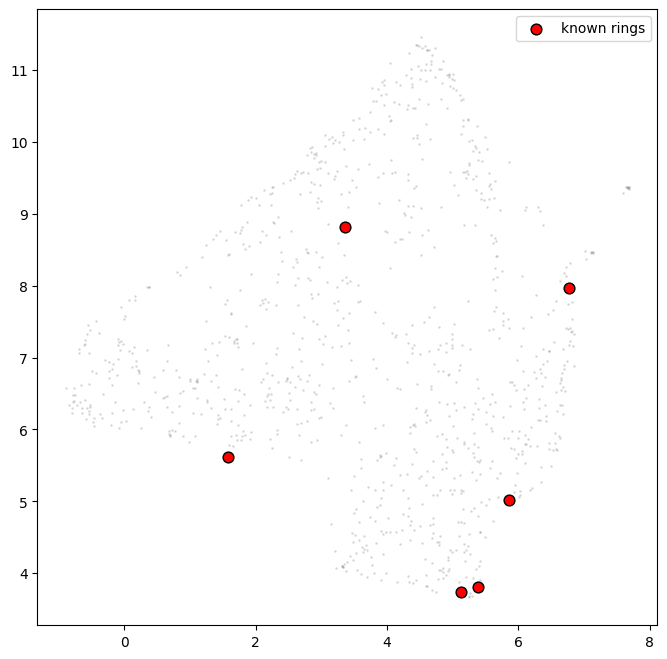

In [14]:
import numpy as np, umap, matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

feat_cols = [f"feat_pca_{i}" for i in range(40)]
X = rep[feat_cols].to_numpy(dtype=np.float32)
seed_rows = hit[hit._merge == "both"]
seed_idx = rep.index[rep.id_clean.isin(seed_rows.id_str)].to_numpy()


nn = NearestNeighbors(n_neighbors=11, metric="euclidean").fit(X)
dist, nbr = nn.kneighbors(X[seed_idx])
for s, d, n in zip(seed_idx, dist, nbr):
    print(rep.id_clean[s], "-> neighbours:", [rep.id_clean[j] for j in n[1:4]], "mean dist", d[1:].mean())

rng = np.random.default_rng(0)
sample = np.unique(np.concatenate([rng.choice(len(X), 1000, replace=False), seed_idx]))
reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=0)
Z = reducer.fit_transform(X[sample])

pos = {j: k for k, j in enumerate(sample)}
plt.figure(figsize=(8, 8))
plt.scatter(Z[:, 0], Z[:, 1], s=1, alpha=0.2, c="grey")
zs = np.array([Z[pos[j]] for j in seed_idx])
plt.scatter(zs[:, 0], zs[:, 1], s=60, c="red", edgecolor="k", label="known rings")
plt.legend(); plt.savefig("../outputs/umap_seeds.png", dpi=150)

In [17]:
import os, glob, re, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import fits
from astropy.visualization import ImageNormalize, PercentileInterval, AsinhStretch
from sklearn.neighbors import NearestNeighbors
sys.path.append("../notebooks")                 # where cutout_utils.py lives
import cutout_utils as ut
from astroquery.esa.euclid.core import Euclid

# ids and features
rep["id_clean"] = rep.id_str.str.replace("NEG", "-", regex=False).str.split("_").str[-1]
rep["id_num"] = rep.id_clean.astype("int64")
X = rep[[f"feat_pca_{i}" for i in range(40)]].to_numpy(dtype=np.float32)

# the six seeds that are in the representations
seed_ids = hit.loc[hit._merge == "both", "object_id"].astype("int64")
seed_idx = rep.index[rep.id_num.isin(seed_ids)].to_numpy()
print(len(seed_idx), "seeds;", X.shape, "feature matrix")          # expect 6 seeds, (380111, 40)

# neighbour search in the full 40-d space
nn = NearestNeighbors(n_neighbors=11, metric="euclidean").fit(X)
cat_pos = pd.read_parquet("zenodo/morphology_catalogue.parquet",
                          columns=["object_id", "right_ascension", "declination"])

6 seeds; (380111, 40) feature matrix


In [19]:
print(cat_pos.object_id.dtype, cat_pos.object_id.iloc[:3].tolist())     # to see what the text looks like
cat_pos["object_id"] = (cat_pos.object_id.astype(str)
                        .str.replace("NEG", "-", regex=False)
                        .astype("int64"))

str ['-520564092291261106', '-520560290287655192', '-520559452289115027']


In [20]:
dist40, nb40 = nn.kneighbors(X[seed_idx])           # rep rows; column 0 is the seed itself

groups = []
for i in range(len(seed_idx)):
    groups += [(f"seed{i}", r) for r in nb40[i]]
groups += [("random", r) for r in np.random.default_rng(3).choice(len(rep), 20, replace=False)]

tg = pd.DataFrame(groups, columns=["group", "rep_row"])
tg["object_id"] = rep.id_num.to_numpy()[tg.rep_row]
tg = tg.merge(cat_pos, on="object_id", how="left")
print(tg.group.value_counts())                       # six groups of 11, and random 20
print(tg[["right_ascension", "declination"]].isna().sum().to_dict())   # should be 0
print("mean neighbour distance per seed:", np.round(dist40[:, 1:].mean(axis=1), 1))
tg.to_csv("../data/neighbour_targets.csv", index=False)

group
random    20
seed0     11
seed1     11
seed2     11
seed3     11
seed4     11
seed5     11
Name: count, dtype: int64
{'right_ascension': 0, 'declination': 0}
mean neighbour distance per seed: [8.1 6.6 6.7 4.7 8.7 7.1]


In [21]:
Euclid.login()
ids = ",".join(str(i) for i in tg.object_id.unique())
query = f"""(SELECT right_ascension, declination, segmentation_area, flux_vis_1fwhm_aper,
            ellipticity, kron_radius, segmentation_map_id
            FROM catalogue.mer_catalogue WHERE object_id IN ({ids}))"""
folder = "../outputs/region_cutouts/"
os.makedirs(folder, exist_ok=True)
df = ut.getFiles(product_type="mosaic", sources=query, instrument_name="VIS", segmentation_map_id=True)
print(len(df), "sources found; expect", tg.object_id.nunique())
ut.makeCutoutsByTile(df, output_location=folder, cutout_size=0.8*u.arcmin)
print(len(glob.glob(folder + "*MOSAIC-VIS*.fits")), "cutout files")

INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  nsuthar
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  nsuthar
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Query finished. [astroquery.utils.tap.core]
Found 86 query results
86 sources found; expect 86


Number of files processed:   0%|          | 0/73 [00:00<?, ?it/s]

Made cutout MOSAIC-VIS_TILE102018213-CUTOUT_59.1963409_-51.4656882.fits
Made cutout MOSAIC-VIS_TILE102019123-CUTOUT_56.956638_-50.62505.fits
Made cutout MOSAIC-VIS_TILE102019127-CUTOUT_59.5096659_-50.6365878.fits
Made cutout MOSAIC-VIS_TILE102019127-CUTOUT_60.0699962_-50.5714106.fits
Made cutout MOSAIC-VIS_TILE102019128-CUTOUT_60.9198979_-50.3691772.fits
Made cutout MOSAIC-VIS_TILE102019587-CUTOUT_56.8744577_-49.8562316.fits
Made cutout MOSAIC-VIS_TILE102019593-CUTOUT_61.2285495_-50.2267174.fits
Made cutout MOSAIC-VIS_TILE102019596-CUTOUT_63.6522161_-49.8974712.fits
Made cutout MOSAIC-VIS_TILE102020054-CUTOUT_55.7704255_-49.3896688.fits
Made cutout MOSAIC-VIS_TILE102020056-CUTOUT_57.1638051_-49.5794575.fits
Made cutout MOSAIC-VIS_TILE102020062-CUTOUT_61.6797383_-49.6187025.fits
Made cutout MOSAIC-VIS_TILE102020063-CUTOUT_62.1676126_-49.5831454.fits
Made cutout MOSAIC-VIS_TILE102020529-CUTOUT_56.8647445_-49.015412.fits
Made cutout MOSAIC-VIS_TILE102020529-CUTOUT_56.8624037_-49.0160899.f

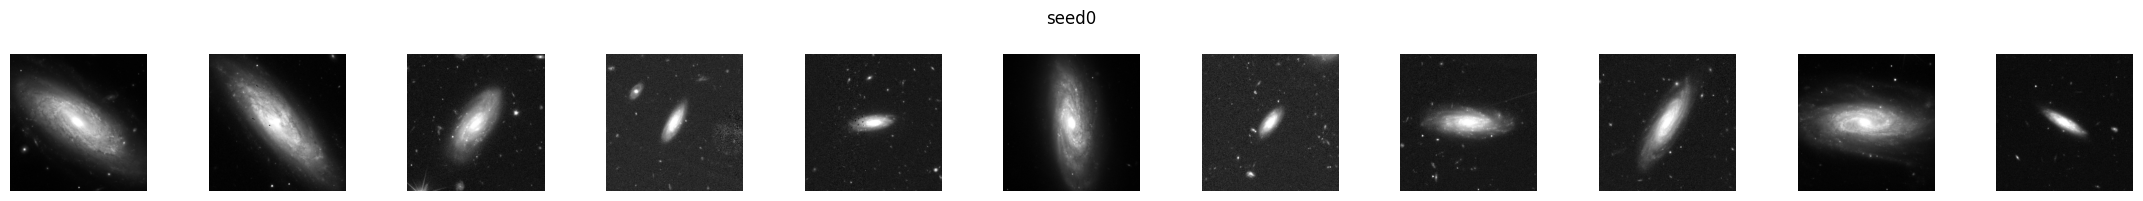

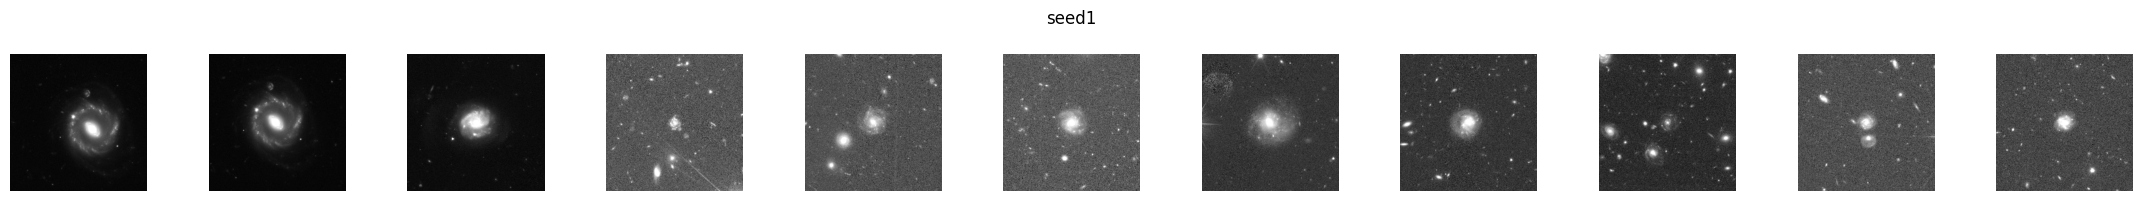

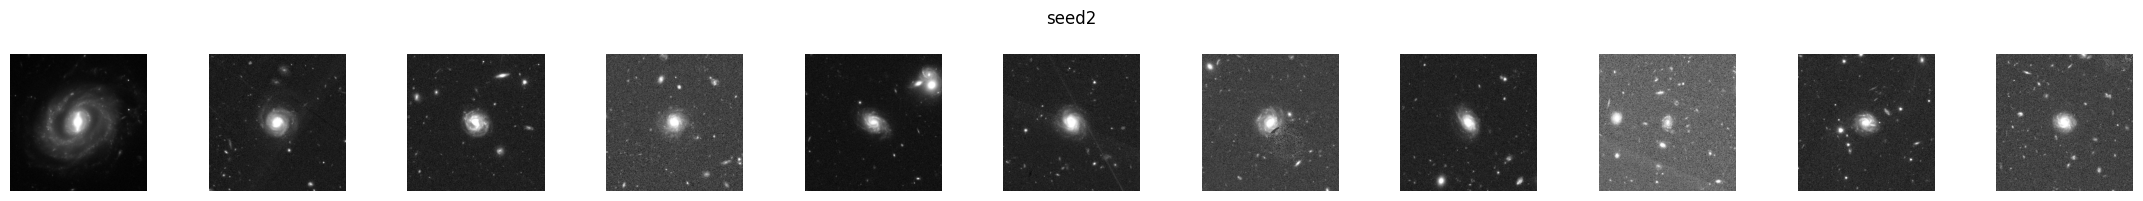

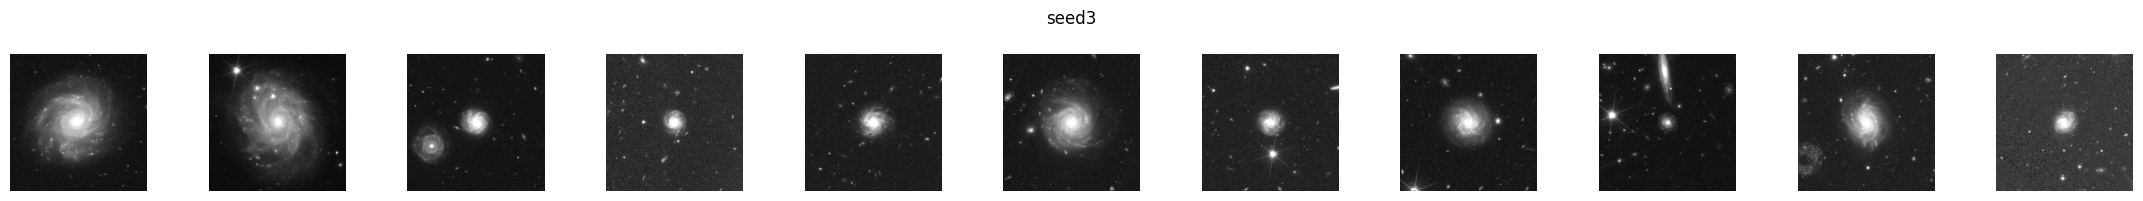

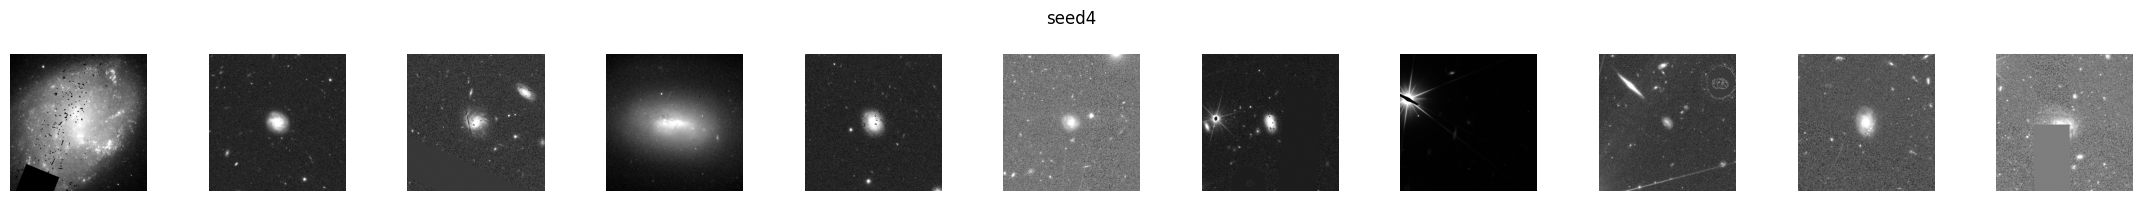

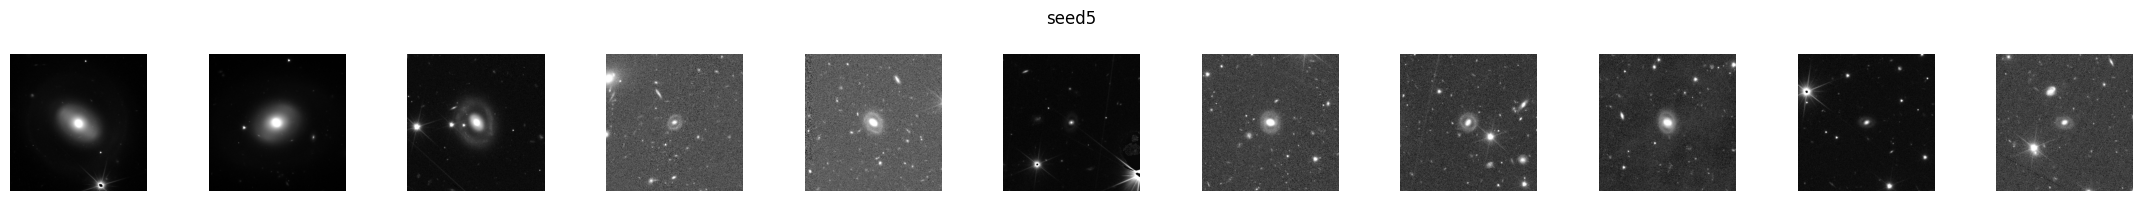

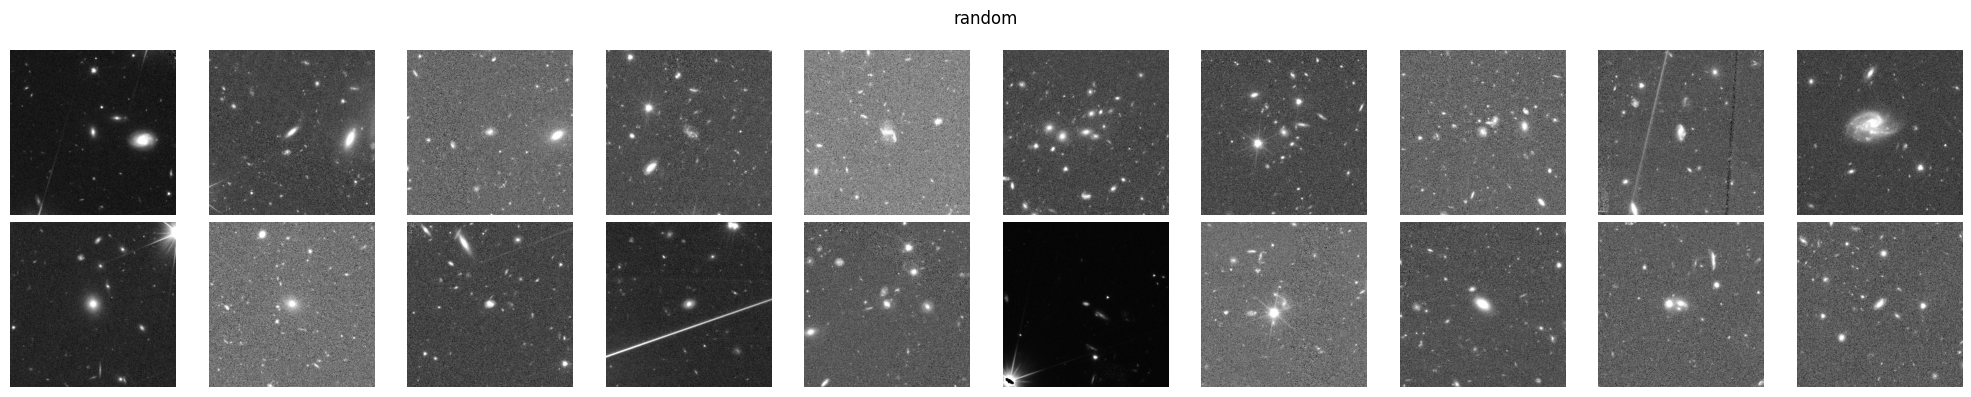

In [22]:
files = sorted(glob.glob(folder + "*MOSAIC-VIS*.fits"))
fpos = np.array([[float(x) for x in re.search(r"CUTOUT_(-?[\d.]+)_(-?[\d.]+)\.fits", f).groups()]
                 for f in files])
def find(ra, dec):
    d = np.hypot((fpos[:, 0] - ra) * np.cos(np.radians(dec)), fpos[:, 1] - dec)
    k = d.argmin()
    return files[k] if d[k] < 1e-3 else None

for g, sub in tg.groupby("group", sort=False):
    cols = 11 if g != "random" else 10
    nr = int(np.ceil(len(sub) / cols))
    fig, ax = plt.subplots(nr, cols, figsize=(2*cols, 2*nr), squeeze=False)
    for a in ax.flat: a.axis("off")
    for a, (_, r) in zip(ax.flat, sub.iterrows()):
        f = find(r.right_ascension, r.declination)
        if f is None:
            a.set_title("missing", fontsize=7); continue
        img = fits.getdata(f, ext=0)
        a.imshow(img, cmap="gray", origin="lower",
                 norm=ImageNormalize(img, interval=PercentileInterval(99.5), stretch=AsinhStretch()))
    fig.suptitle(g); plt.tight_layout(); plt.savefig(f"../outputs/{g}.png", dpi=110); plt.show()

In [23]:
s5 = seed_idx[5]
print("seed5 object_id:", rep.id_num.iloc[s5])

nn50 = NearestNeighbors(n_neighbors=51).fit(X)
d50, nb50 = nn50.kneighbors(X[[s5]])
tg5 = pd.DataFrame({"group": "seed5_k50", "rank": range(51),
                    "rep_row": nb50[0], "dist": d50[0]})
tg5["object_id"] = rep.id_num.to_numpy()[tg5.rep_row]
tg5 = tg5.merge(cat_pos, on="object_id", how="left")
print(tg5[["right_ascension", "declination"]].isna().sum().to_dict())
tg5.to_csv("../data/seed5_neighbours50.csv", index=False)

seed5 object_id: 2654157551644988910
{'right_ascension': 0, 'declination': 0}


In [24]:
Euclid.login()                                    # skip if you're still logged in; type the password at the prompt
ids5 = ",".join(str(i) for i in tg5.object_id.unique())
query5 = f"""(SELECT right_ascension, declination, segmentation_area, flux_vis_1fwhm_aper,
             ellipticity, kron_radius, segmentation_map_id
             FROM catalogue.mer_catalogue WHERE object_id IN ({ids5}))"""

folder5 = "../outputs/seed5_cutouts/"
os.makedirs(folder5, exist_ok=True)

df5 = ut.getFiles(product_type="mosaic", sources=query5,
                  instrument_name="VIS", segmentation_map_id=True)
print(len(df5), "sources found; expect", tg5.object_id.nunique())
ut.makeCutoutsByTile(df5, output_location=folder5, cutout_size=0.8*u.arcmin)
print(len(glob.glob(folder5 + "*MOSAIC-VIS*.fits")), "cutout files")

INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  nsuthar
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  nsuthar
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Query finished. [astroquery.utils.tap.core]
Found 51 query results
51 sources found; expect 51


Number of files processed:   0%|          | 0/46 [00:00<?, ?it/s]

Made cutout MOSAIC-VIS_TILE102019128-CUTOUT_60.9267924_-50.3307387.fits
Made cutout MOSAIC-VIS_TILE102019129-CUTOUT_61.7148634_-50.3706621.fits
Made cutout MOSAIC-VIS_TILE102019129-CUTOUT_61.8273512_-50.5197574.fits
Made cutout MOSAIC-VIS_TILE102019590-CUTOUT_59.4516954_-49.8257497.fits
Made cutout MOSAIC-VIS_TILE102020056-CUTOUT_57.1563916_-49.4454613.fits
Made cutout MOSAIC-VIS_TILE102020532-CUTOUT_59.0790394_-49.0470654.fits
Made cutout MOSAIC-VIS_TILE102020535-CUTOUT_61.4678465_-49.169943.fits
Made cutout MOSAIC-VIS_TILE102021008-CUTOUT_57.0991755_-48.4808019.fits
Made cutout MOSAIC-VIS_TILE102021009-CUTOUT_57.2280304_-48.640888.fits
Made cutout MOSAIC-VIS_TILE102021492-CUTOUT_58.0462723_-47.8940239.fits
Made cutout MOSAIC-VIS_TILE102021503-CUTOUT_66.0679087_-47.8565495.fits
Made cutout MOSAIC-VIS_TILE102021504-CUTOUT_66.7521443_-47.967245.fits
Made cutout MOSAIC-VIS_TILE102021981-CUTOUT_58.5825598_-47.4840223.fits
Made cutout MOSAIC-VIS_TILE102021985-CUTOUT_61.7737303_-47.3372762.

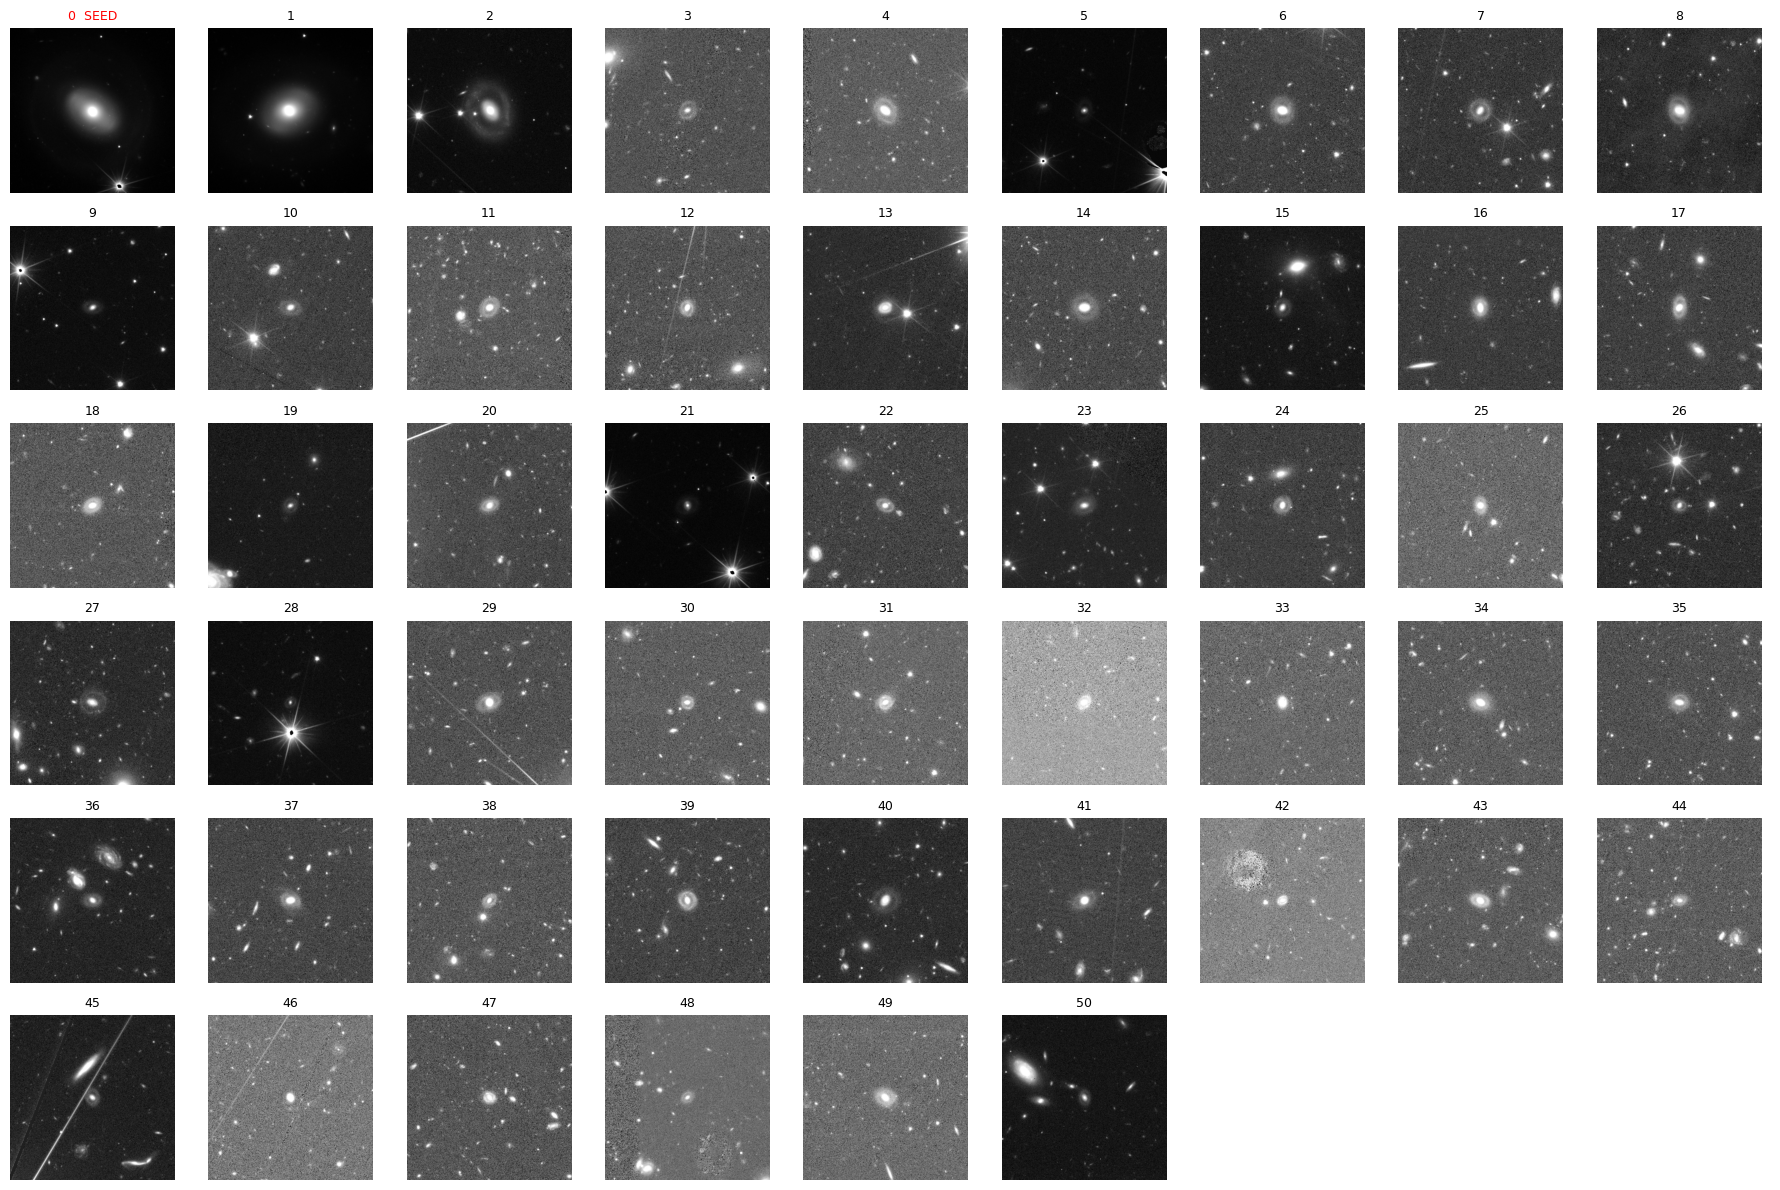

In [25]:
files5 = sorted(glob.glob(folder5 + "*MOSAIC-VIS*.fits"))
fpos5 = np.array([[float(x) for x in re.search(r"CUTOUT_(-?[\d.]+)_(-?[\d.]+)\.fits", f).groups()]
                  for f in files5])
def find5(ra, dec):
    d = np.hypot((fpos5[:, 0] - ra) * np.cos(np.radians(dec)), fpos5[:, 1] - dec)
    k = d.argmin()
    return files5[k] if d[k] < 1e-3 else None

fig, ax = plt.subplots(6, 9, figsize=(18, 12))
for a in ax.flat: a.axis("off")
for a, (_, r) in zip(ax.flat, tg5.iterrows()):
    f = find5(r.right_ascension, r.declination)
    if f is None:
        a.set_title(f"{int(r['rank'])} missing", fontsize=8); continue
    img = fits.getdata(f, ext=0)
    a.imshow(img, cmap="gray", origin="lower",
             norm=ImageNormalize(img, interval=PercentileInterval(99.5), stretch=AsinhStretch()))
    a.set_title(f"{int(r['rank'])}" + ("  SEED" if r["rank"] == 0 else ""),
                fontsize=9, color="red" if r["rank"] == 0 else "black")
plt.tight_layout(); plt.savefig("../outputs/seed5_k50.png", dpi=120); plt.show()

In [36]:
print(os.path.getsize("../data/cutouts_jpg_gz_arcsinh_vis_y.tar"))

209715200


In [37]:
tg5[["rank", "key"]].to_csv("../data/seed5_keys.csv", index=False)
print(tg5.key.head(3).tolist())

KeyError: "['key'] not in index"